# 06 — Ajuste y evaluación final

## Objetivo

Cerrar el recorrido: ajustar los hiperparámetros del modelo elegido (Gradient Boosting),
entrenar la versión final y medirla **una sola vez** en el conjunto de prueba (2026), que no
se ha usado en ningún momento del proyecto. Después, entender el modelo: qué variables usa,
si sus probabilidades son confiables y dónde se equivoca.

El cuadernillo termina con las conclusiones generales del proyecto.

In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline

from src.config import MODELS_DIR, PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET, SEED = config["features"], config["target"], config["seed"]
MIN_HISTORY = config["min_train_history"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])

## 1. Datos para el ajuste

Hasta ahora la validación (2025) sirvió para comparar modelos. Esa decisión ya está tomada,
así que 2025 puede sumarse al entrenamiento: es el año más parecido al que se va a predecir.

Se aplica el mismo filtro del cuadernillo 05 (ambos equipos con 30 o más mapas previos) y se
ordenan los mapas cronológicamente, porque la validación cruzada que sigue depende del orden.

In [2]:
development = pd.concat([train, val])
development = (development[development["min_maps_played"] >= MIN_HISTORY]
               .sort_values(["stage_block", "match_id", "game_id"]))
X_dev, y_dev = development[FEATURES], development[TARGET]
print(f"Mapas para ajuste y entrenamiento final: {len(development)}")
development["year"].value_counts().sort_index().to_frame("maps").T

Mapas para ajuste y entrenamiento final: 6188


year,2021,2022,2023,2024,2025
maps,1608,2017,585,896,1082


## 2. Ajuste de hiperparámetros

**Qué se ajusta.** Los hiperparámetros del Gradient Boosting que controlan su complejidad:

| Hiperparámetro | Qué controla |
|---|---|
| `learning_rate` | Cuánto corrige cada árbol; valores bajos aprenden despacio y generalizan mejor |
| `max_iter` | Número de árboles |
| `max_depth` | Profundidad de cada árbol: cuántas variables puede combinar |
| `min_samples_leaf` | Mapas mínimos por hoja; valores altos evitan memorizar casos aislados |
| `l2_regularization` | Penalización que encoge las predicciones de cada hoja |

**Cómo se valida.** Con validación cruzada *temporal* (`TimeSeriesSplit`): los datos se
cortan en bloques consecutivos y cada modelo se entrena con los bloques anteriores y se mide
en el siguiente. Una validación cruzada normal mezclaría mapas futuros en el entrenamiento.

```
Corte 1:  [entrena][valida]
Corte 2:  [   entrena   ][valida]
Corte 3:  [      entrena      ][valida]   …
```

**Cómo se busca.** Búsqueda aleatoria de 40 combinaciones, optimizando el log loss (el
criterio fijado en el cuadernillo 05). Se prefiere a la búsqueda en rejilla porque explora
más valores distintos de cada hiperparámetro con el mismo número de entrenamientos.

In [3]:
cv = TimeSeriesSplit(n_splits=5)
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=SEED),
    param_distributions={
        "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
        "max_iter": [50, 100, 200, 300],
        "max_depth": [2, 3, 4],
        "min_samples_leaf": [20, 50, 100, 200],
        "l2_regularization": [0, 0.1, 1, 10],
    },
    n_iter=40, cv=cv, scoring="neg_log_loss", random_state=SEED, n_jobs=-1,
)
search.fit(X_dev, y_dev)
print("Mejor combinación:", search.best_params_)
print(f"Log loss en validación cruzada: {-search.best_score_:.4f}")

Mejor combinación: {'min_samples_leaf': 200, 'max_iter': 50, 'max_depth': 3, 'learning_rate': 0.02, 'l2_regularization': 0}
Log loss en validación cruzada: 0.6825


In [4]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results["log_loss"] = -cv_results["mean_test_score"]
param_cols = [c for c in cv_results.columns if c.startswith("param_")]
cv_table = cv_results.sort_values("log_loss")[param_cols + ["log_loss", "std_test_score"]]
cv_table.to_csv(TABLES_DIR / "06_busqueda_hiperparametros.csv", index=False)
pd.concat([cv_table.head(5), cv_table.tail(3)]).round(4)

,param_min_samples_leaf,param_max_iter,param_max_depth,param_learning_rate,param_l2_regularization,log_loss,std_test_score
11,200,50,3,0.02,0.0,0.6825,0.0037
25,200,100,3,0.01,0.0,0.6826,0.0036
18,50,50,3,0.02,10.0,0.6829,0.0027
10,20,50,2,0.03,1.0,0.6829,0.0038
5,50,100,3,0.01,0.1,0.6830,0.0020
12,100,200,3,0.10,0.0,0.7099,0.0176
35,20,100,4,0.10,1.0,0.7120,0.0154
1,50,300,4,0.10,0.1,0.7507,0.0378


Las mejores combinaciones son las más conservadoras: árboles poco profundos, tasa de
aprendizaje baja y hojas grandes. Las peores son las de mayor capacidad. Es coherente con lo
visto en el cuadernillo 05: con poca señal, la complejidad se convierte en sobreajuste.

Se mide, con la misma validación cruzada, cuánto mejoró el ajuste respecto a la
configuración del cuadernillo 05 y respecto a la línea base de una variable.

In [5]:
def cv_log_loss(model, columns):
    return -cross_val_score(model, development[columns], y_dev, cv=cv, scoring="neg_log_loss").mean()

cv_comparison = pd.Series({
    "Base: logística de 1 variable": cv_log_loss(
        make_pipeline(SimpleImputer(strategy="median"), LogisticRegression()), ["diff_winrate"]),
    "Gradient Boosting (configuración del cuadernillo 05)": cv_log_loss(
        HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, early_stopping=True,
                                       random_state=SEED), FEATURES),
    "Gradient Boosting ajustado": -search.best_score_,
}, name="log_loss_cv")
cv_comparison.round(4).to_frame()

,log_loss_cv
Base: logística de 1 variable,0.6844
Gradient Boosting (configuración del cuadernillo 05),0.6856
Gradient Boosting ajustado,0.6825


El ajuste mejora el log loss de 0.6856 a 0.6825 y deja al modelo ligeramente por delante de
la línea base de una variable (0.6844). Son diferencias en el tercer decimal: el ajuste
ayuda, pero no cambia el panorama. La combinación ganadora es un modelo deliberadamente
pequeño: 50 árboles de profundidad 3, con hojas de al menos 200 mapas.

## 3. Modelo final

`RandomizedSearchCV` ya reentrenó la mejor combinación con todos los datos de desarrollo
(2021–2025 filtrados). Ese es el modelo final; se guarda en `models/`.

In [6]:
final_model = search.best_estimator_
joblib.dump(final_model, MODELS_DIR / "final_model.joblib", compress=3)
final_model

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.02
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",50
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",200
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values.

## 4. Evaluación en el conjunto de prueba (2026)

Este es el único momento del proyecto en que se usan los 886 mapas de 2026. Ninguna decisión
anterior —variables, filtro de entrenamiento, modelo, hiperparámetros— los vio. El resultado
que salga aquí es el que se reporta, sin volver atrás a retocar nada.

Se evalúan también las líneas base, reentrenadas con los mismos datos de desarrollo, porque
el número del modelo solo significa algo en comparación con ellas.

In [7]:
X_test, y_test = test[FEATURES], test[TARGET]
final_proba = final_model.predict_proba(X_test)[:, 1]

results = {}
results["Base: clase mayoritaria"] = evaluate(y_test, np.full(len(test), y_dev.mean()))

rule_proba = np.select([test["diff_winrate"] > 0, test["diff_winrate"] < 0], [1.0, 0.0], default=0.5)
rule_decided = rule_proba != 0.5
results["Base: regla del winrate"] = {
    "accuracy": ((rule_proba > 0.5) == (y_test == 1))[rule_decided].mean(), "roc_auc": np.nan, "log_loss": np.nan}

one_variable = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
one_variable.fit(development[["diff_winrate"]], y_dev)
one_variable_proba = one_variable.predict_proba(test[["diff_winrate"]])[:, 1]
results["Base: logística de 1 variable"] = evaluate(y_test, one_variable_proba)

results["Modelo final: Gradient Boosting ajustado"] = evaluate(y_test, final_proba)

final_results = pd.DataFrame(results).T
final_results.to_csv(TABLES_DIR / "06_resultados_finales.csv")
final_results.round(4)

,accuracy,roc_auc,log_loss
Base: clase mayoritaria,0.4966,0.5000,0.6932
Base: regla del winrate,0.5603,NaN,NaN
Base: logística de 1 variable,0.5474,0.5869,0.6798
Modelo final: Gradient Boosting ajustado,0.5711,0.6061,0.6796


### ¿Qué tan firme es el resultado?

Con 886 mapas, cualquier métrica tiene un margen de error apreciable. Se estima con
*bootstrap*: se remuestrean los mapas de prueba 2 000 veces y se recalculan las métricas.
Se calcula también la **diferencia** de log loss entre el modelo y la logística de una
variable sobre las mismas remuestras, que es la forma correcta de comparar dos modelos
evaluados en los mismos mapas.

In [8]:
rng = np.random.default_rng(SEED)
y_array = y_test.to_numpy()
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_array), len(y_array))
    model_metrics = evaluate(y_array[idx], final_proba[idx])
    base_metrics = evaluate(y_array[idx], one_variable_proba[idx])
    boot.append({"accuracy": model_metrics["accuracy"], "roc_auc": model_metrics["roc_auc"],
                 "log_loss": model_metrics["log_loss"],
                 "log_loss_minus_baseline": model_metrics["log_loss"] - base_metrics["log_loss"],
                 "accuracy_minus_baseline": model_metrics["accuracy"] - base_metrics["accuracy"]})
boot = pd.DataFrame(boot)
intervals = boot.quantile([0.025, 0.5, 0.975]).T.set_axis(["IC 2.5 %", "mediana", "IC 97.5 %"], axis=1)
intervals.to_csv(TABLES_DIR / "06_intervalos_bootstrap.csv")
intervals.round(4)

,IC 2.5 %,mediana,IC 97.5 %
accuracy,0.5395,0.5722,0.6038
roc_auc,0.5687,0.6064,0.6442
log_loss,0.6726,0.6796,0.6865
log_loss_minus_baseline,-0.0061,-0.0000,0.0056
accuracy_minus_baseline,0.0056,0.0237,0.0418


Lectura de los resultados en prueba:

- **Exactitud: 57.1 %** (IC 95 %: 54.0 %–60.4 %). El intervalo queda completo por encima del
  50 %: el modelo predice mejor que el azar, sin duda razonable.
- **Frente a las líneas base en exactitud:** supera a la regla del winrate (56.0 %) y a la
  logística de una variable (54.7 %). La ventaja sobre esta última es de 2.4 puntos, con un
  intervalo de 0.6 a 4.2 puntos que no incluye el cero.
- **Frente a las líneas base en log loss:** empate. 0.6796 contra 0.6798; el intervalo de la
  diferencia (−0.006 a +0.006) está centrado en cero. Las probabilidades del modelo no son
  mejores que las de una logística con una sola variable.
- **ROC-AUC: 0.606**, frente a 0.587 de la línea base: el modelo ordena algo mejor los mapas.

El resultado en prueba es muy parecido al de validación (57.5 % y log loss 0.680 en 2025), lo
que indica que el procedimiento no se sobreajustó a la validación.

## 5. Entender el modelo

### 5.1 Matriz de confusión y curva ROC

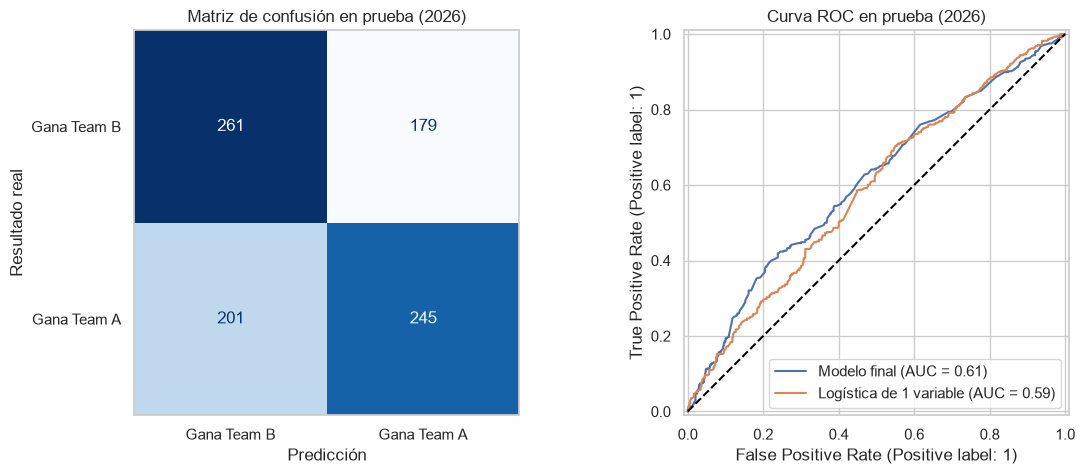

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, final_proba > 0.5, ax=axes[0], cmap="Blues", colorbar=False,
                                        display_labels=["Gana Team B", "Gana Team A"])
axes[0].set(title="Matriz de confusión en prueba (2026)", xlabel="Predicción", ylabel="Resultado real")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, final_proba, name="Modelo final", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, one_variable_proba, name="Logística de 1 variable", ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black")
axes[1].set(title="Curva ROC en prueba (2026)")
save_fig("06_matriz_confusion_y_roc")
plt.show()

La matriz muestra aciertos y errores repartidos de forma similar entre las dos clases: el
modelo no tiene preferencia por Team A ni por Team B, como debe ser después del intercambio
aleatorio del cuadernillo 03.

### 5.2 ¿Se puede confiar en las probabilidades?

Se agrupan los mapas según la probabilidad que el modelo le dio a Team A y se compara con la
proporción de veces que Team A realmente ganó.

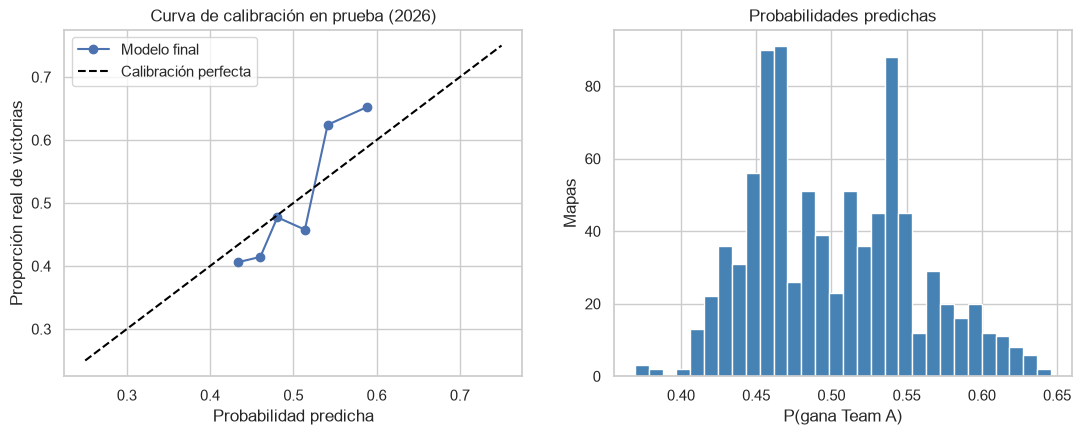

Rango de probabilidades: 0.37 – 0.65


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
observed, predicted = calibration_curve(y_test, final_proba, n_bins=6, strategy="quantile")
axes[0].plot(predicted, observed, marker="o", label="Modelo final")
axes[0].plot([0.25, 0.75], [0.25, 0.75], linestyle="--", color="black", label="Calibración perfecta")
axes[0].set(title="Curva de calibración en prueba (2026)", xlabel="Probabilidad predicha",
            ylabel="Proporción real de victorias")
axes[0].legend()
axes[1].hist(final_proba, bins=30, color="steelblue")
axes[1].set(title="Probabilidades predichas", xlabel="P(gana Team A)", ylabel="Mapas")
save_fig("06_calibracion")
plt.show()
print(f"Rango de probabilidades: {final_proba.min():.2f} – {final_proba.max():.2f}")

El modelo es **prudente**: nunca da menos de 37 % ni más de 65 % a un equipo, y la mayoría de
sus predicciones están cerca del 50 %. La curva de calibración sigue la diagonal de forma
aproximada. Es el comportamiento opuesto al de la primera logística del cuadernillo 05, que
repartía probabilidades de 1 % a 99 %. Si acaso, este modelo se queda algo corto: en el grupo
de mapas al que da 59 % en promedio, Team A gana el 65 %.

### 5.3 ¿Qué variables usa el modelo?

Importancia por permutación sobre el conjunto de prueba: cuánto empeora el log loss al
desordenar cada variable.

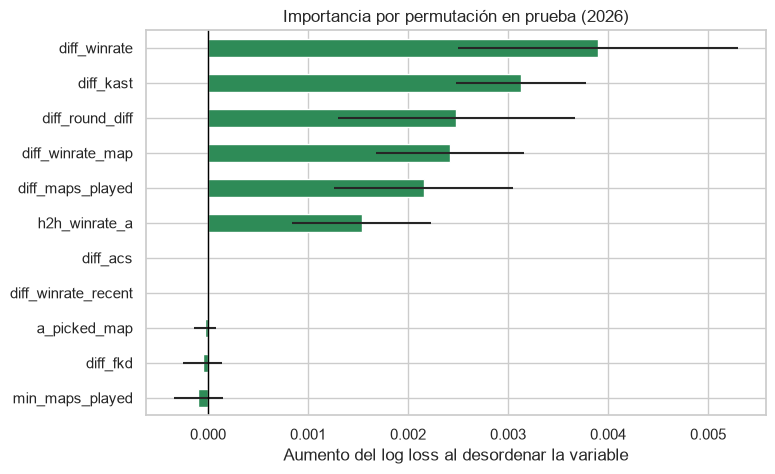

,diff_winrate,diff_kast,diff_round_diff,diff_winrate_map,diff_maps_played,h2h_winrate_a,diff_winrate_recent,diff_acs,a_picked_map,diff_fkd,min_maps_played
mean,0.0039,0.0031,0.0025,0.0024,0.0022,0.0015,0.0,0.0,-0.0000,-0.0001,-0.0001
std,0.0014,0.0007,0.0012,0.0007,0.0009,0.0007,0.0,0.0,0.0001,0.0002,0.0002


In [11]:
importance = permutation_importance(final_model, X_test, y_test, scoring="neg_log_loss",
                                    n_repeats=50, random_state=SEED)
importance = pd.DataFrame({"mean": importance.importances_mean, "std": importance.importances_std},
                          index=FEATURES).sort_values("mean")
importance.to_csv(TABLES_DIR / "06_importancia_variables.csv")
ax = importance["mean"].plot.barh(xerr=importance["std"], color="seagreen", figsize=(8, 5))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Importancia por permutación en prueba (2026)", xlabel="Aumento del log loss al desordenar la variable")
save_fig("06_importancia_variables")
plt.show()
importance.sort_values("mean", ascending=False).round(4).T

El modelo se apoya en seis variables: el winrate histórico (`diff_winrate`), la consistencia
individual (`diff_kast`), el margen de rondas (`diff_round_diff`), el winrate en el mapa
concreto (`diff_winrate_map`), la experiencia (`diff_maps_played`) y los enfrentamientos
directos (`h2h_winrate_a`). Las otras cinco —forma reciente, ACS, duelos de apertura, quién
eligió el mapa y `min_maps_played`— tienen importancia nula: con solo 50 árboles pequeños el
modelo no llegó a usarlas, o las usó sin efecto.

Todas las importancias son pequeñas (milésimas de log loss), lo que confirma que ninguna
variable es decisiva por sí sola y que varias cuentan una historia parecida.

### 5.4 ¿Dónde acierta y dónde se equivoca?

**Según la confianza del modelo.** Si las probabilidades significan algo, el modelo debería
acertar más cuando está más seguro.

In [12]:
analysis = test.assign(proba=final_proba, correct=(final_proba > 0.5) == (y_test == 1))
analysis["confidence"] = (analysis["proba"] - 0.5).abs() + 0.5
by_confidence = analysis.groupby(pd.cut(analysis["confidence"], [0.5, 0.55, 0.6, 0.65, 1.0], include_lowest=True),
                                 observed=True)["correct"].agg(accuracy="mean", maps="size")
by_confidence.round(3)

,accuracy,maps
confidence,,
"(0.499, 0.55]",0.532,592
"(0.55, 0.6]",0.648,250
"(0.6, 0.65]",0.659,44


Las probabilidades tienen contenido real. En los dos tercios de los mapas donde el modelo
apenas se inclina por un equipo (confianza menor a 55 %) acierta el 53 %: prácticamente una
moneda, y el modelo lo "sabe". En el tercio restante, donde ve un favorito, acierta cerca
del 65 %.

**Según el historial disponible.** ¿Predice mejor cuando ambos equipos tienen más mapas previos?

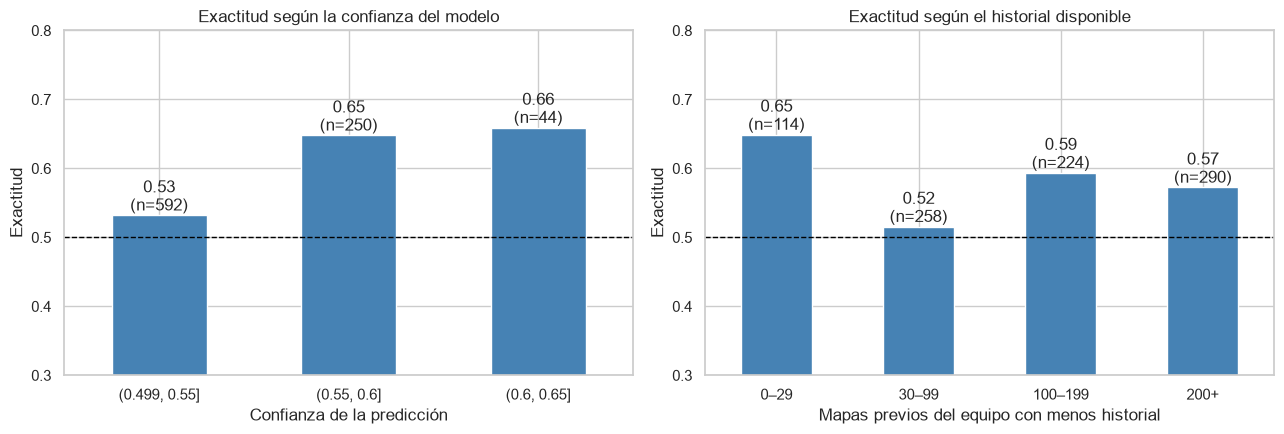

,accuracy,maps
min_maps_played,,
0–29,0.649,114
30–99,0.516,258
100–199,0.594,224
200+,0.572,290


In [13]:
by_history = analysis.groupby(pd.cut(analysis["min_maps_played"], [-1, 29, 99, 199, 1000],
                                     labels=["0–29", "30–99", "100–199", "200+"]),
                              observed=True)["correct"].agg(accuracy="mean", maps="size")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, table, title, xlabel in [
        (axes[0], by_confidence, "Exactitud según la confianza del modelo", "Confianza de la predicción"),
        (axes[1], by_history, "Exactitud según el historial disponible", "Mapas previos del equipo con menos historial")]:
    table["accuracy"].plot.bar(ax=ax, color="steelblue")
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel=xlabel, ylabel="Exactitud", ylim=(0.3, 0.8))
    ax.bar_label(ax.containers[0], labels=[f"{a:.2f}\n(n={n})" for a, n in zip(table["accuracy"], table["maps"])])
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
save_fig("06_analisis_de_errores")
plt.show()
by_history.round(3)

Más historial no implica mejores predicciones. El tramo con mejor exactitud es el de menos
historial (0–29 mapas, 65 %): ahí están los cruces entre un equipo establecido y uno nuevo
en el circuito, que son los más desiguales y por tanto los más fáciles. Entre equipos con
mucho historial los partidos son parejos y la exactitud se queda entre 52 % y 59 %. Con
grupos de 100 a 300 mapas, estas diferencias tienen bastante ruido.

## Conclusiones

### Del cuadernillo

1. **Modelo final:** Gradient Boosting con 50 árboles de profundidad 3, tasa de aprendizaje
   0.02 y hojas de al menos 200 mapas, entrenado con 6 188 mapas de 2021–2025 en los que ambos
   equipos tenían 30 o más mapas previos. Guardado en `models/final_model.joblib`.
2. **Resultado en prueba (886 mapas de 2026, usados una sola vez):**

   | Modelo | Exactitud | ROC-AUC | Log loss |
   |---|---|---|---|
   | Base: clase mayoritaria | 0.497 | 0.500 | 0.693 |
   | Base: regla del winrate | 0.560 | — | — |
   | Base: logística de 1 variable | 0.547 | 0.587 | 0.680 |
   | **Modelo final** | **0.571** | **0.606** | **0.680** |

3. **Qué significa:** el modelo acierta el ganador del 57.1 % de los mapas (IC 95 %:
   54.0 %–60.4 %), claramente mejor que el azar y algo mejor que las reglas simples en
   exactitud y en capacidad de ordenar. En calidad de probabilidades empata con una logística
   de una sola variable.
4. **Sus probabilidades son honestas:** van de 37 % a 65 %, están razonablemente calibradas,
   y cuando el modelo ve un favorito (un tercio de los mapas) acierta cerca del 65 %.
5. **El ajuste de hiperparámetros confirmó que menos es más:** las mejores combinaciones son
   las más simples y las de mayor capacidad se sobreajustan.

### Del proyecto

**Objetivo:** predecir qué equipo gana un mapa de VCT antes de que se juegue.
**Respuesta:** se puede, con una ventaja modesta. El resultado de un mapa entre equipos
profesionales es difícil de anticipar con estadísticas históricas: el 28 % de los mapas se
decide por tres rondas o menos, y los equipos de las ligas actuales son parejos.

Lo que el recorrido deja, paso a paso:

- **00–01:** el dataset no trae fechas y los IDs no ordenan los partidos dentro de una etapa.
  De ahí salió la regla que protege todo el proyecto: el historial solo usa etapas anteriores.
- **02:** Team A gana más por cómo la web ordena a los equipos, no por jugar mejor. Se
  corrigió intercambiando equipos al azar.
- **03:** las estadísticas del propio mapa "predicen" con 94 % de acierto porque son
  consecuencia del resultado. Las variables históricas, sin fuga, dan una señal real pero pequeña.
- **04:** 11 variables bastan; el resto era redundante o sin señal.
- **05:** entrenar con partidos que no se parecen a los que se quiere predecir arruina la
  calibración. Y las líneas base simples son muy difíciles de batir.
- **06:** 57.1 % de exactitud en un año completo que el modelo nunca vio.

**Limitaciones**

- **Sin fechas:** el orden temporal se aproxima con IDs y por etapas. Dentro de una etapa
  larga (una fase de grupos de varias semanas) el modelo no ve los resultados más recientes.
- **Historial por nombre de equipo:** si un equipo cambia de jugadores, conserva su historial;
  si cambia de nombre, lo pierde.
- **Datos de entrenamiento escasos para el problema real:** de 27 368 mapas, solo 6 188
  corresponden a cruces entre equipos con historial.
- **2026 es una temporada parcial** (886 mapas): los intervalos de confianza son anchos.
- **No se usa la composición de agentes ni el lado inicial**, que se conocen justo antes del mapa.

**Mejoras posibles**

- Construir el historial **por jugador** y agregarlo según la alineación de cada partido.
- Ponderar más los mapas recientes (un rating tipo Elo, o medias con decaimiento) en lugar
  de promedios de toda la historia.
- Conseguir las fechas reales de los partidos para usar también el historial dentro de la etapa.
- Incorporar la composición de agentes de cada equipo en el mapa.

Con lo que se tiene hasta ahora, el plan actual queda completo: un modelo reproducible,
evaluado sin fuga de datos y con un resultado que se puede defender tal cual es.